In [ ]:
import os
import zipfile
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

print("TensorFlow Version:", tf.__version__)
print("GPU Available:", tf.config.list_physical_devices("GPU"))

TensorFlow Version: 2.21.0
GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
from google.colab import files
uploaded = files.upload()

Saving Sunflower Growth Stage Image Dataset for Phenologi.zip to Sunflower Growth Stage Image Dataset for Phenologi.zip


In [ ]:
import zipfile
import os

zip_file = list(uploaded.keys())[0]
extract_path = "/content/sunflower_dataset"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_file, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset Extracted Successfully!")

Dataset Extracted Successfully!


In [ ]:
for root, dirs, files in os.walk(extract_path):
    level = root.replace(extract_path, "").count(os.sep)

    if level > 2:
        continue

    indent = "  " * level
    print(f"{indent}{os.path.basename(root)}/")

    for file in files[:5]:
        print(f"{indent}  {file}")

sunflower_dataset/
  Sunflower Growth Stage Image Dataset for Phenologi/
    Sunflower Stage Original.zip
    Stage_Aug.zip


In [ ]:
image_extensions = ('.jpg', '.jpeg', '.png', '.bmp', '.webp')

total_images = 0

for root, dirs, files in os.walk(extract_path):
    for file in files:
        if file.lower().endswith(image_extensions):
            total_images += 1

print("Total Images:", total_images)

Total Images: 0


In [ ]:
import os
import zipfile

base_path = "/content/sunflower_dataset/Sunflower Growth Stage Image Dataset for Phenologi"

zip_path = os.path.join(base_path, "Stage_Aug.zip")

dataset_path = "/content/sunflower_images"

os.makedirs(dataset_path, exist_ok=True)

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(dataset_path)

print("Stage_Aug Dataset Extracted Successfully!")

Stage_Aug Dataset Extracted Successfully!


In [ ]:
for root, dirs, files in os.walk(dataset_path):
    level = root.replace(dataset_path, "").count(os.sep)

    if level > 2:
        continue

    indent = "  " * level

    print(f"{indent}{os.path.basename(root)}/")

    for file in files[:3]:
        print(f"{indent}  {file}")

sunflower_images/
  Stage_Aug/
    Stage1 (Young_Bud)/
      rotated_30_135.jpg
      rotated_15_27.jpg
      center_scaled_1.1_432.jpg
    Stage2 (Mature_Bud)/
      rotated_30_135.jpg
      rotated_15_27.jpg
      center_scaled_1.1_432.jpg
    Stage3 (Early_Bloom)/
      rotated_30_135.jpg
      rotated_15_27.jpg
      center_scaled_1.1_432.jpg
    Stage4 (Full_Bloom)/
      rotated_30_135.jpg
      rotated_15_27.jpg
      center_scaled_1.1_432.jpg
    Stage5 (Wilted)/
      rotated_30_135.jpg
      rotated_15_27.jpg
      center_scaled_1.1_432.jpg


In [ ]:
image_extensions = ('.jpg', '.jpeg', '.png', '.bmp', '.webp')

total_images = 0

for root, dirs, files in os.walk(dataset_path):
    for file in files:
        if file.lower().endswith(image_extensions):
            total_images += 1

print("Total Images:", total_images)

Total Images: 2500


In [ ]:
for root, dirs, files in os.walk(dataset_path):

    images = [
        f for f in files
        if f.lower().endswith(image_extensions)
    ]

    if len(images) > 0:
        print(os.path.basename(root), ":", len(images))

Stage1 (Young_Bud) : 500
Stage2 (Mature_Bud) : 500
Stage3 (Early_Bloom) : 500
Stage4 (Full_Bloom) : 500
Stage5 (Wilted) : 500


In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

data_dir = "/content/sunflower_images/Stage_Aug"

class_names = sorted([
    d for d in os.listdir(data_dir)
    if os.path.isdir(os.path.join(data_dir, d))
])

print("Total Classes:", len(class_names))
print("Class Names:")

for i, name in enumerate(class_names):
    print(i, ":", name)

Total Classes: 5
Class Names:
0 : Stage1 (Young_Bud)
1 : Stage2 (Mature_Bud)
2 : Stage3 (Early_Bloom)
3 : Stage4 (Full_Bloom)
4 : Stage5 (Wilted)


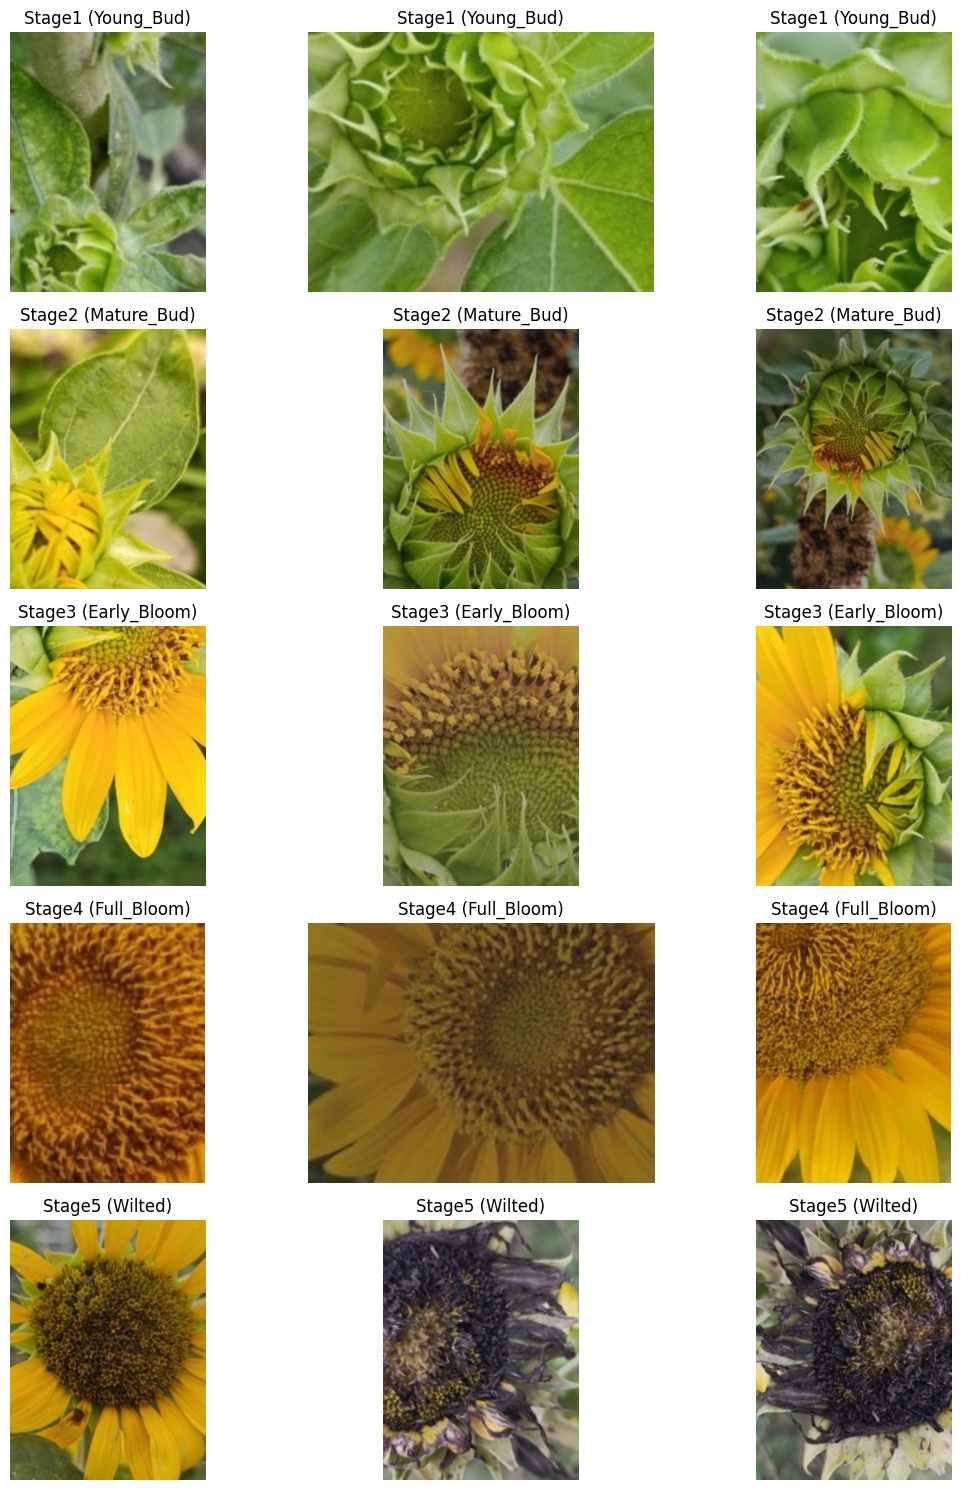

In [ ]:
plt.figure(figsize=(12, 15))

for i, class_name in enumerate(class_names):

    class_path = os.path.join(data_dir, class_name)

    images = sorted([
        f for f in os.listdir(class_path)
        if f.lower().endswith(('.jpg', '.jpeg', '.png'))
    ])

    for j in range(3):

        img_path = os.path.join(class_path, images[j])
        img = Image.open(img_path).convert("RGB")

        plt.subplot(5, 3, i * 3 + j + 1)
        plt.imshow(img)
        plt.title(class_name)
        plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
image_sizes = []

for class_name in class_names:

    class_path = os.path.join(data_dir, class_name)

    images = os.listdir(class_path)

    for img_name in images[:20]:

        img_path = os.path.join(class_path, img_name)

        try:
            with Image.open(img_path) as img:
                image_sizes.append(img.size)
        except Exception:
            continue

print("Sample Image Dimensions:")
print(image_sizes[:10])

print("Unique Image Sizes:")
print(set(image_sizes))

Sample Image Dimensions:
[(480, 638), (479, 854), (479, 854), (480, 638), (480, 638), (638, 480), (854, 479), (480, 638), (479, 854), (638, 480)]
Unique Image Sizes:
{(638, 480), (854, 479), (640, 480), (480, 638), (479, 854), (480, 640)}


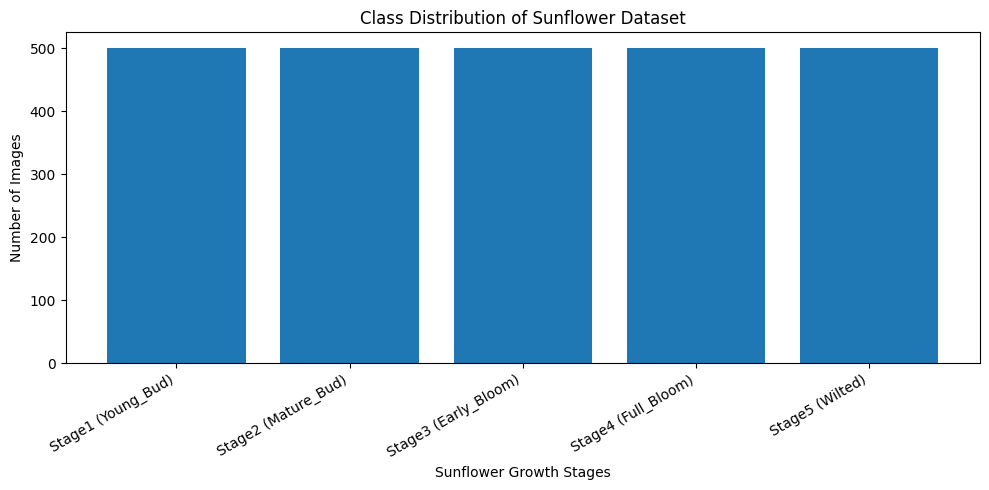

In [ ]:
image_counts = []

for class_name in class_names:

    class_path = os.path.join(data_dir, class_name)

    count = len([
        f for f in os.listdir(class_path)
        if f.lower().endswith(('.jpg', '.jpeg', '.png'))
    ])

    image_counts.append(count)

plt.figure(figsize=(10, 5))

plt.bar(class_names, image_counts)

plt.xlabel("Sunflower Growth Stages")
plt.ylabel("Number of Images")
plt.title("Class Distribution of Sunflower Dataset")

plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

In [ ]:
import os
import zipfile

base_path = "/content/sunflower_dataset/Sunflower Growth Stage Image Dataset for Phenologi"

original_zip = os.path.join(
    base_path, "Sunflower Stage Original.zip"
)

original_path = "/content/sunflower_original"

os.makedirs(original_path, exist_ok=True)

with zipfile.ZipFile(original_zip, "r") as zip_ref:
    zip_ref.extractall(original_path)

print("Original Dataset Extracted Successfully!")

Original Dataset Extracted Successfully!


In [ ]:
for root, dirs, files in os.walk(original_path):

    level = root.replace(original_path, "").count(os.sep)

    if level > 3:
        continue

    indent = "  " * level
    print(f"{indent}{os.path.basename(root)}/")

    image_files = [
        f for f in files
        if f.lower().endswith(
            (".jpg", ".jpeg", ".png", ".bmp", ".webp")
        )
    ]

    if image_files:
        print(f"{indent}  Images: {len(image_files)}")
        print(f"{indent}  Example: {image_files[0]}")

sunflower_original/
  Sunflower Stage Original/
    Stage1 (Young_Bud)/
      Images: 238
      Example: Young_Bud_111.jpg
    Stage2 (Mature_Bud)/
      Images: 272
      Example: Mature_Bud_27.jpg
    Stage3 (Early_Bloom)/
      Images: 218
      Example: Early_Bloom_107.jpg
    Stage4 (Full_Bloom)/
      Images: 213
      Example: Full_Bloom_126.jpg
    Stage5 (Wilted)/
      Images: 314
      Example: Wilted_297.jpg


Original Size: (480, 638)
Resized Shape: (128, 128, 3)
Minimum Pixel: 0.0
Maximum Pixel: 0.9098039215686274


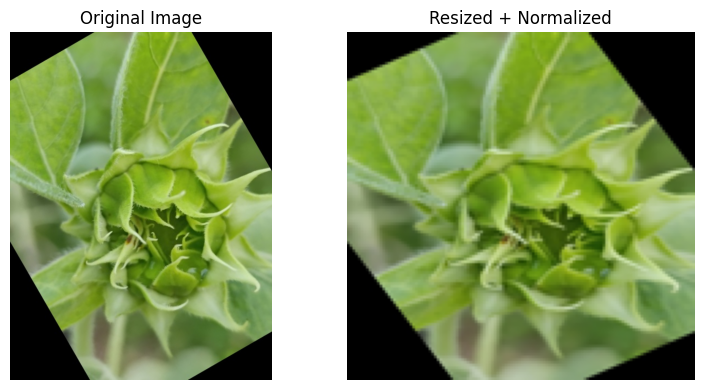

In [ ]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

sample_path = os.path.join(
    data_dir,
    class_names[0],
    os.listdir(os.path.join(data_dir, class_names[0]))[0]
)

img = Image.open(sample_path).convert("RGB")

resized_img = img.resize((128, 128))

normalized_img = np.array(resized_img) / 255.0

print("Original Size:", img.size)
print("Resized Shape:", normalized_img.shape)
print("Minimum Pixel:", normalized_img.min())
print("Maximum Pixel:", normalized_img.max())

plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.imshow(img)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(normalized_img)
plt.title("Resized + Normalized")
plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import os

original_dir = "/content/sunflower_original/Sunflower Stage Original"

class_names = sorted([
    folder for folder in os.listdir(original_dir)
    if os.path.isdir(os.path.join(original_dir, folder))
])

print("Total Classes:", len(class_names))
print("Classes:", class_names)

Total Classes: 5
Classes: ['Stage1 (Young_Bud)', 'Stage2 (Mature_Bud)', 'Stage3 (Early_Bloom)', 'Stage4 (Full_Bloom)', 'Stage5 (Wilted)']


In [ ]:
import os
import shutil
from sklearn.model_selection import train_test_split

split_dir = "/content/sunflower_split"

image_extensions = (
    ".jpg", ".jpeg", ".png", ".bmp", ".webp"
)

for class_name in class_names:

    source_dir = os.path.join(original_dir, class_name)

    images = sorted([
        img for img in os.listdir(source_dir)
        if img.lower().endswith(image_extensions)
    ])

    train_imgs, temp_imgs = train_test_split(
        images,
        test_size=0.30,
        random_state=42
    )

    val_imgs, test_imgs = train_test_split(
        temp_imgs,
        test_size=0.50,
        random_state=42
    )

    for split_name, split_images in [
        ("train", train_imgs),
        ("val", val_imgs),
        ("test", test_imgs)
    ]:

        destination = os.path.join(
            split_dir, split_name, class_name
        )

        os.makedirs(destination, exist_ok=True)

        for img in split_images:
            shutil.copy2(
                os.path.join(source_dir, img),
                os.path.join(destination, img)
            )

print("Dataset Splitting Completed!")

Dataset Splitting Completed!


In [ ]:
for split_name in ["train", "val", "test"]:

    split_path = os.path.join(split_dir, split_name)

    total = 0

    print("\n", split_name.upper())

    for class_name in class_names:

        class_path = os.path.join(
            split_path, class_name
        )

        count = len([
            f for f in os.listdir(class_path)
            if f.lower().endswith(image_extensions)
        ])

        total += count
        print(class_name, ":", count)

    print("Total:", total)


 TRAIN
Stage1 (Young_Bud) : 166
Stage2 (Mature_Bud) : 190
Stage3 (Early_Bloom) : 152
Stage4 (Full_Bloom) : 149
Stage5 (Wilted) : 219
Total: 876

 VAL
Stage1 (Young_Bud) : 36
Stage2 (Mature_Bud) : 41
Stage3 (Early_Bloom) : 33
Stage4 (Full_Bloom) : 32
Stage5 (Wilted) : 47
Total: 189

 TEST
Stage1 (Young_Bud) : 36
Stage2 (Mature_Bud) : 41
Stage3 (Early_Bloom) : 33
Stage4 (Full_Bloom) : 32
Stage5 (Wilted) : 48
Total: 190


In [ ]:
import tensorflow as tf
from tensorflow.keras import layers

IMG_SIZE = (128, 128)
BATCH_SIZE = 32
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(split_dir, "train"),
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    shuffle=True,
    seed=SEED
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(split_dir, "val"),
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(split_dir, "test"),
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    shuffle=False
)

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.10),
    layers.RandomZoom(0.10)
], name="training_augmentation")

print("Dataset Loaded Successfully!")

Found 876 files belonging to 5 classes.
Found 189 files belonging to 5 classes.
Found 190 files belonging to 5 classes.
Dataset Loaded Successfully!


In [ ]:
print("Training Batches:", len(train_ds))
print("Validation Batches:", len(val_ds))
print("Testing Batches:", len(test_ds))

for images, labels in train_ds.take(1):
    print("Image Batch Shape:", images.shape)
    print("Label Batch Shape:", labels.shape)
    print("Pixel Range:", tf.reduce_min(images).numpy(),
          tf.reduce_max(images).numpy())

Training Batches: 28
Validation Batches: 6
Testing Batches: 6
Image Batch Shape: (32, 128, 128, 3)
Label Batch Shape: (32, 5)
Pixel Range: 0.0 255.0


In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models

cnn_model = models.Sequential([

    # Input Layer
    layers.Input(shape=(128, 128, 3)),

    # Data Augmentation (Training Only)
    data_augmentation,

    # Normalization
    layers.Rescaling(1./255),

    # First Convolution Block
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Second Convolution Block
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Third Convolution Block
    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Flatten Layer
    layers.Flatten(),

    # Fully Connected Layer
    layers.Dense(128, activation='relu'),

    # Dropout for reducing overfitting
    layers.Dropout(0.5),

    # Output Layer (5 Classes)
    layers.Dense(5, activation='softmax')

])

print("CNN Model Created Successfully!")

CNN Model Created Successfully!


In [ ]:
cnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ training_augmentation           │ (None, 128, 128, 3)    │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,305,285 (12.61 MB)

 Trainable params: 3,305,285 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
cnn_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("Model Compiled Successfully!")

Model Compiled Successfully!


In [ ]:
history = cnn_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20
)

Epoch 1/20
28/28 ━━━━━━━━━━━━━━━━━━━━ 10s 120ms/step - accuracy: 0.4600 - loss: 1.2603 - val_accuracy: 0.7513 - val_loss: 0.7035
Epoch 2/20
28/28 ━━━━━━━━━━━━━━━━━━━━ 2s 69ms/step - accuracy: 0.7180 - loss: 0.6963 - val_accuracy: 0.8624 - val_loss: 0.3724
Epoch 3/20
28/28 ━━━━━━━━━━━━━━━━━━━━ 2s 62ms/step - accuracy: 0.8174 - loss: 0.4860 - val_accuracy: 0.7249 - val_loss: 0.6283
Epoch 4/20
28/28 ━━━━━━━━━━━━━━━━━━━━ 2s 62ms/step - accuracy: 0.8208 - loss: 0.4212 - val_accuracy: 0.9471 - val_loss: 0.1624
Epoch 5/20
28/28 ━━━━━━━━━━━━━━━━━━━━ 3s 62ms/step - accuracy: 0.8687 - loss: 0.3591 - val_accuracy: 0.7143 - val_loss: 0.8385
Epoch 6/20
28/28 ━━━━━━━━━━━━━━━━━━━━ 3s 70ms/step - accuracy: 0.8630 - loss: 0.3675 - val_accuracy: 0.8942 - val_loss: 0.2503
Epoch 7/20
28/28 ━━━━━━━━━━━━━━━━━━━━ 3s 87ms/step - accuracy: 0.8607 - loss: 0.3604 - val_accuracy: 0.9206 - val_loss: 0.2527
Epoch 8/20
28/28 ━━━━━━━━━━━━━━━━━━━━ 2s 62ms/step - accuracy: 0.8881 - loss: 0.3094 - val_accuracy: 0.9524 -

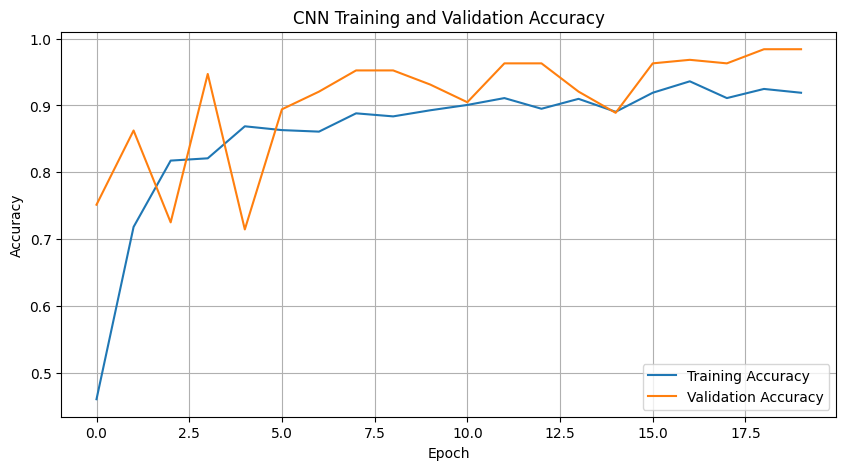

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    history.history['accuracy'],
    label='Training Accuracy'
)

plt.plot(
    history.history['val_accuracy'],
    label='Validation Accuracy'
)

plt.title('CNN Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

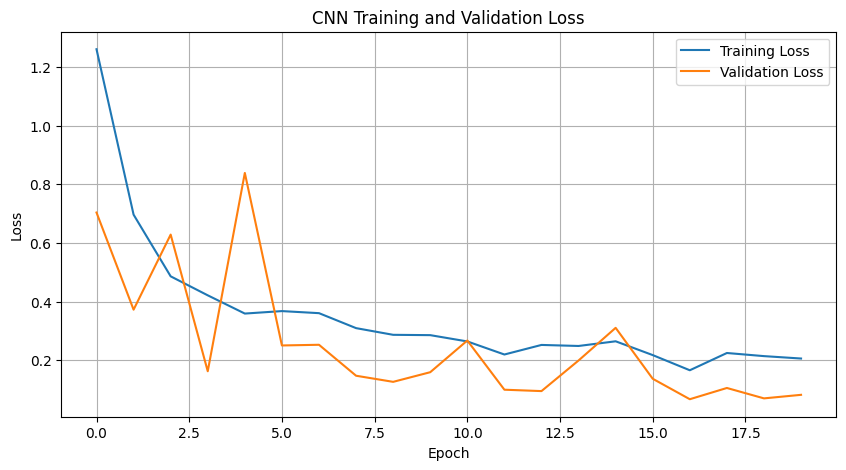

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(
    history.history['loss'],
    label='Training Loss'
)

plt.plot(
    history.history['val_loss'],
    label='Validation Loss'
)

plt.title('CNN Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
test_loss, test_accuracy = cnn_model.evaluate(
    test_ds,
    verbose=1
)

print("Test Accuracy: {:.2f}%".format(test_accuracy * 100))
print("Test Loss: {:.4f}".format(test_loss))

6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 112ms/step - accuracy: 0.9526 - loss: 0.1808
Test Accuracy: 95.26%
Test Loss: 0.1808


In [ ]:
import numpy as np

y_true = []
y_pred = []

for images, labels in test_ds:

    predictions = cnn_model.predict(
        images,
        verbose=0
    )

    y_true.extend(
        np.argmax(labels.numpy(), axis=1)
    )

    y_pred.extend(
        np.argmax(predictions, axis=1)
    )

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print("Actual Labels:", y_true[:10])
print("Predicted Labels:", y_pred[:10])

Actual Labels: [0 0 0 0 0 0 0 0 0 0]
Predicted Labels: [0 0 0 0 0 0 0 0 0 0]


In [ ]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names,
        digits=4
    )
)

                      precision    recall  f1-score   support

  Stage1 (Young_Bud)     1.0000    0.9722    0.9859        36
 Stage2 (Mature_Bud)     0.9524    0.9756    0.9639        41
Stage3 (Early_Bloom)     0.9706    1.0000    0.9851        33
 Stage4 (Full_Bloom)     0.9032    0.8750    0.8889        32
     Stage5 (Wilted)     0.9375    0.9375    0.9375        48

            accuracy                         0.9526       190
           macro avg     0.9527    0.9521    0.9522       190
        weighted avg     0.9525    0.9526    0.9524       190



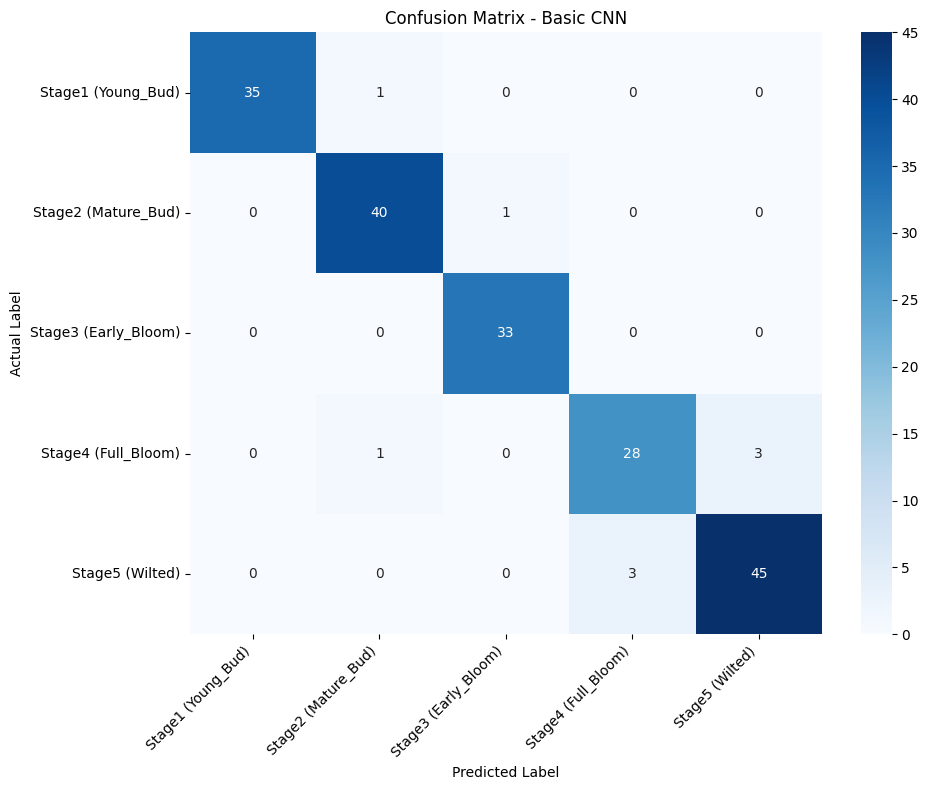

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Confusion Matrix - Basic CNN")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

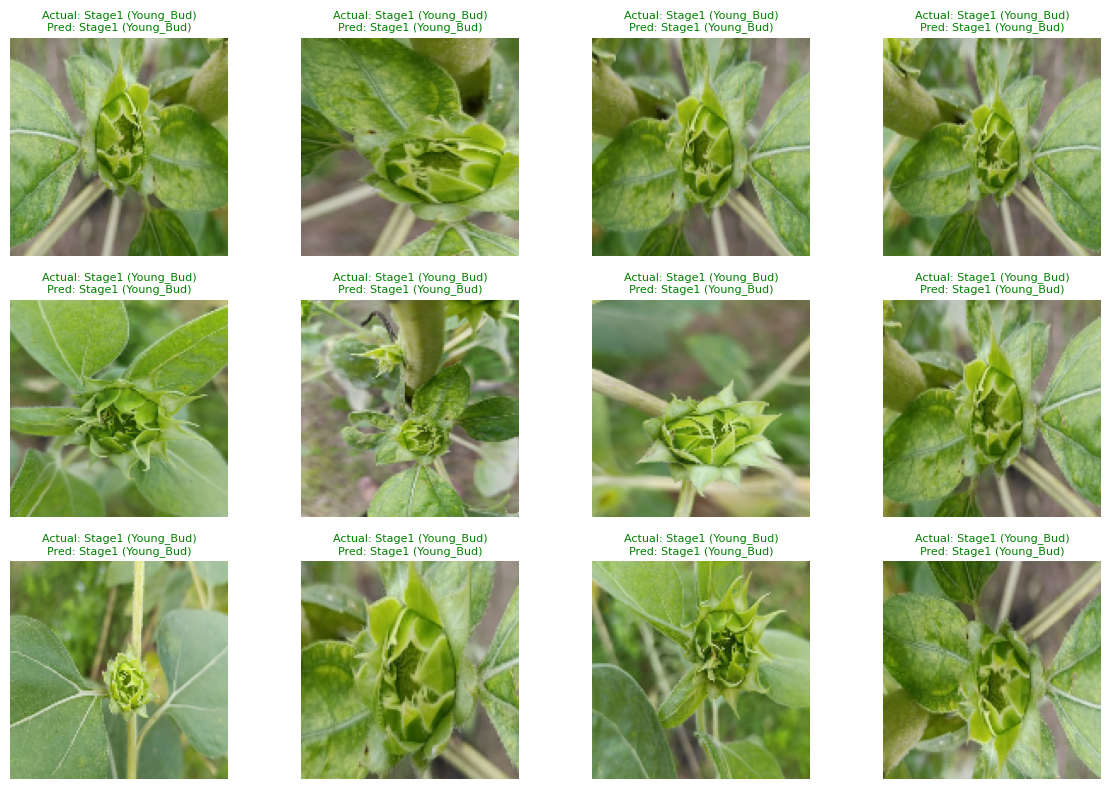

In [ ]:
plt.figure(figsize=(12, 8))

for images, labels in test_ds.take(1):

    predictions = cnn_model.predict(
        images,
        verbose=0
    )

    for i in range(12):

        plt.subplot(3, 4, i + 1)

        plt.imshow(images[i].numpy().astype("uint8"))

        actual = class_names[
            np.argmax(labels[i].numpy())
        ]

        predicted = class_names[
            np.argmax(predictions[i])
        ]

        color = "green" if actual == predicted else "red"

        plt.title(
            f"Actual: {actual}\nPred: {predicted}",
            color=color,
            fontsize=8
        )

        plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
cnn_model.save("/content/sunflower_basic_cnn.keras")

print("CNN Model Saved Successfully!")

CNN Model Saved Successfully!


In [ ]:
from google.colab import files

files.download("/content/sunflower_basic_cnn.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

import os
from google.colab import files

test_folder = "/content/sunflower_split/test/Stage4 (Full_Bloom)"

image_name = sorted(os.listdir(test_folder))[0]

image_path = os.path.join(test_folder, image_name)

files.download(image_path)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Saving Full_Bloom_103.jpg to Full_Bloom_103.jpg
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 258ms/step


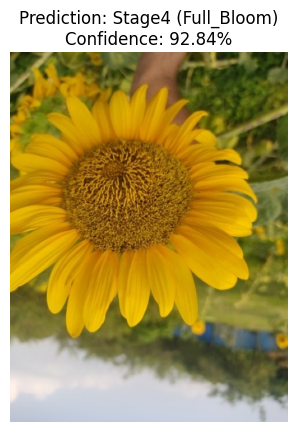

Predicted Stage: Stage4 (Full_Bloom)
Confidence: 92.84%


In [ ]:
from google.colab import files
from tensorflow.keras.utils import load_img, img_to_array
import numpy as np
import matplotlib.pyplot as plt

uploaded = files.upload()

image_path = list(uploaded.keys())[0]

img = load_img(
    image_path,
    target_size=(128, 128)
)

img_array = img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)

predictions = cnn_model.predict(img_array)

predicted_index = np.argmax(predictions[0])
predicted_class = class_names[predicted_index]
confidence = np.max(predictions[0]) * 100

plt.imshow(load_img(image_path))
plt.title(
    f"Prediction: {predicted_class}\n"
    f"Confidence: {confidence:.2f}%"
)
plt.axis("off")
plt.show()

print("Predicted Stage:", predicted_class)
print("Confidence: {:.2f}%".format(confidence))

In [ ]:
cnn_model.save(
    "/content/sunflower_basic_cnn.keras"
)

print("Model Saved Successfully!")

Model Saved Successfully!


In [ ]:
import pandas as pd

results = pd.DataFrame({
    "Metric": [
        "Training Accuracy",
        "Validation Accuracy",
        "Test Accuracy",
        "Test Loss",
        "Macro Precision",
        "Macro Recall",
        "Macro F1-score",
        "Weighted F1-score"
    ],
    "Value": [
        0.9189,
        0.9841,
        0.9526,
        0.1808,
        0.9527,
        0.9521,
        0.9522,
        0.9524
    ]
})

results.to_csv(
    "/content/cnn_results.csv",
    index=False
)

print(results)

                Metric   Value
0    Training Accuracy  0.9189
1  Validation Accuracy  0.9841
2        Test Accuracy  0.9526
3            Test Loss  0.1808
4      Macro Precision  0.9527
5         Macro Recall  0.9521
6       Macro F1-score  0.9522
7    Weighted F1-score  0.9524


## Final Result Analysis

A basic CNN model was developed from scratch to classify sunflower images into five growth stages.

The model was trained for 20 epochs using 876 training images, 189 validation images, and 190 testing images.

### Model Performance

- Training Accuracy: 91.89%
- Validation Accuracy: 98.41%
- Test Accuracy: 95.26%
- Test Loss: 0.1808
- Macro Precision: 95.27%
- Macro Recall: 95.21%
- Macro F1-score: 95.22%
- Weighted F1-score: 95.24%

### Conclusion

The basic CNN model achieved 95.26% test accuracy, correctly classifying 181 out of 190 test images. The results demonstrate promising performance for sunflower growth stage classification. Further evaluation on independently collected images is recommended.